In [34]:
import math
import random
import os
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)
os.makedirs("figures", exist_ok=True)

### **Gaussian Mixture Data: Two Classes**

In [35]:
n = 6000
K = 3
weights = [0.34, 0.33, 0.33]

means = [[0.0, 4.0], [-4.0, -2.0], [4.0, -2.0]]
means_2 = [[m[0] + 8.0, m[1] - 2.0] for m in means]
class_means = [means, means_2]

covariances = [
    [[3.0, 0.0], [0.0, 0.5]],     # top: wide horizontal
    [[2.0, 1.5], [1.5, 2.0]],     # bottom-left: positive tilt
    [[2.0, -1.5], [-1.5, 2.0]],   # bottom-right: negative tilt
]

covariances_2 = [
    [[1.0, 0.0], [0.0, 1.0]],     # top: standard
    [[0.5, 0.0], [0.0, 0.5]],     # bottom-left: small
    [[2.0, 0.0], [0.0, 2.0]],     # bottom-right: large
]
class_covariances = [covariances, covariances_2]
covariance_names = [
    ["Wide Horizontal", "Full (+tilt)", "Full (-tilt)"],
    ["Isotropic (Standard)", "Isotropic (Small)", "Isotropic (Large)"],
]

### **Sampling Functions**

Box–Muller: $z_1=\sqrt{-2\ln u_1}\cos(2\pi u_2)$, $z_2=\sqrt{-2\ln u_1}\sin(2\pi u_2)$ with $u_1,u_2\sim U(0,1)$.

For $C=\begin{bmatrix}a&b\\b&c\end{bmatrix}$ the Cholesky factor is $L=\begin{bmatrix}\sqrt a&0\\ b/\sqrt a&\sqrt{c-b^2/a}\end{bmatrix}$, so $x=\mu+Lz$ has covariance $LL^T=C$.

In [36]:
def standard_normal():
    u1 = random.random()
    while u1 == 0:
        u1 = random.random()
    u2 = random.random()
    radius = math.sqrt(-2 * math.log(u1))
    return radius * math.cos(2 * math.pi * u2), radius * math.sin(2 * math.pi * u2)


def cholesky_2x2(C):
    a, b, c = C[0][0], C[0][1], C[1][1]
    l11 = math.sqrt(a)
    l21 = b / l11
    l22 = math.sqrt(c - l21 ** 2)
    return [[l11, 0.0], [l21, l22]]


def shuffled_indices(n):
    order = list(range(n))
    for i in range(n - 1, 0, -1):
        j = int(random.random() * (i + 1))
        order[i], order[j] = order[j], order[i]
    return order


def sample_mixture(n, weights, means, covariances):
    factors = [cholesky_2x2(C) for C in covariances]
    points, labels = [], []
    for _ in range(n):
        u = random.random()
        if u < weights[0]:
            k = 0
        elif u < weights[0] + weights[1]:
            k = 1
        else:
            k = 2

        z1, z2 = standard_normal()
        L = factors[k]
        points.append([means[k][0] + L[0][0] * z1,
                       means[k][1] + L[1][0] * z1 + L[1][1] * z2])
        labels.append(k)
    return np.array(points), np.array(labels)

In [37]:
# GMM data generation - 2 GMMs each has 3 gaussian components.

class_samples = []
class_component_labels = []

for class_index in range(2):
    X, labels = sample_mixture(n, weights, class_means[class_index],
                               class_covariances[class_index])
    class_samples.append(X)
    class_component_labels.append(labels)

print([sample.shape for sample in class_samples])

[(6000, 2), (6000, 2)]


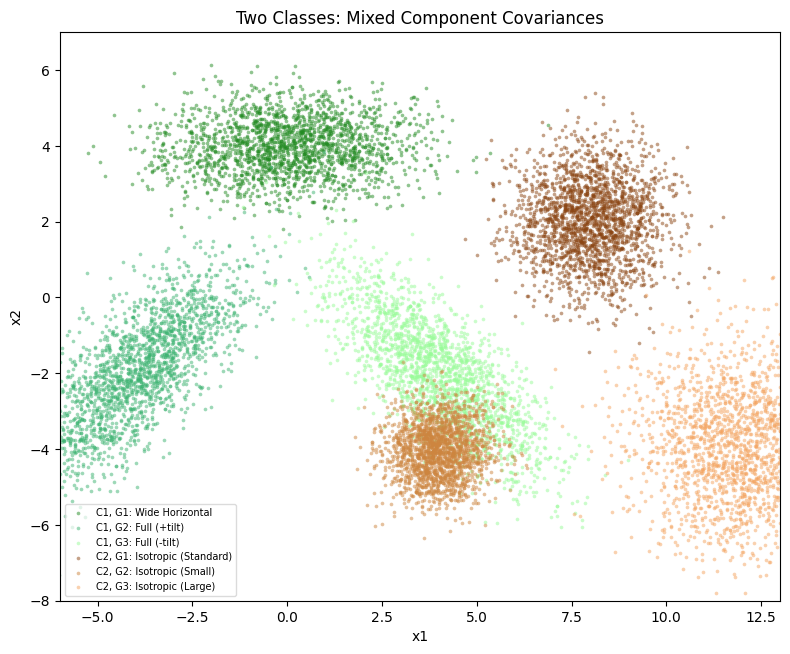

In [38]:
component_colors = [
    ["forestgreen", "mediumseagreen", "palegreen"],
    ["saddlebrown", "peru", "sandybrown"]
]

plt.figure(figsize=(8, 7))
for class_index in range(2):
    for k in range(K):
        sample = class_samples[class_index][class_component_labels[class_index] == k]
        plt.scatter(
            sample[:, 0], sample[:, 1], s=7, alpha=0.5, linewidths=0,
            color=component_colors[class_index][k],
            label=f"C{class_index + 1}, G{k + 1}: {covariance_names[class_index][k]}"
        )

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Two Classes: Mixed Component Covariances")
plt.legend(fontsize=7, framealpha=0.7)
plt.axis("scaled")
plt.xlim(-6, 13)
plt.ylim(-8, 7)
plt.tight_layout()
plt.savefig("figures/generated_data.png", dpi=200)
plt.show()

In [39]:
# train and test split - 80% train and 20% test

train_class_samples = []
test_class_samples = []
train_end = int(0.8 * n)

for samples in class_samples:
    shuffled = samples[shuffled_indices(n)]
    train_class_samples.append(shuffled[:train_end])
    test_class_samples.append(shuffled[train_end:])

### **K-Means Clustering**

In [40]:
class KMeans:
    def __init__(self, K=3):
        self.K = K
        self.centers = None

    def distances(self, X):
        diff = X[:, None, :] - self.centers[None, :, :]
        return np.sum(diff ** 2, axis=2)

    def predict(self, X):
        return np.argmin(self.distances(X), axis=1)

    def distortion(self, X):
        return np.sum(np.min(self.distances(X), axis=1))

    def fit(self, X, max_iterations=100):
        self.centers = X[shuffled_indices(len(X))[:self.K]].astype(float)

        for _ in range(max_iterations):
            labels = self.predict(X)
            new_centers = self.centers.copy()
            for k in range(self.K):
                if np.any(labels == k):
                    new_centers[k] = X[labels == k].mean(axis=0)

            converged = np.max(np.abs(self.centers - new_centers)) < 1e-6
            self.centers = new_centers
            if converged:
                break
        return self

In [41]:
class_models = []

for class_index, samples in enumerate(train_class_samples):
    model = KMeans(K=K).fit(samples)
    class_models.append(model)
    print(f"Class {class_index + 1} centres:\n{model.centers}")
    print(f"Class {class_index + 1} training distortion: {model.distortion(samples):.2f}\n")

Class 1 centres:
[[ 4.09585104 -2.13029558]
 [-4.10697959 -2.09549957]
 [ 0.02436872  3.84435356]]
Class 1 training distortion: 17633.23

Class 2 centres:
[[ 7.99920454  2.01725725]
 [11.99964083 -3.9952502 ]
 [ 4.00093502 -4.04318666]]
Class 2 training distortion: 11218.85



### **Cluster Boundaries Within Each Class**

Learned K-means clusters and Decision Boundary between them.

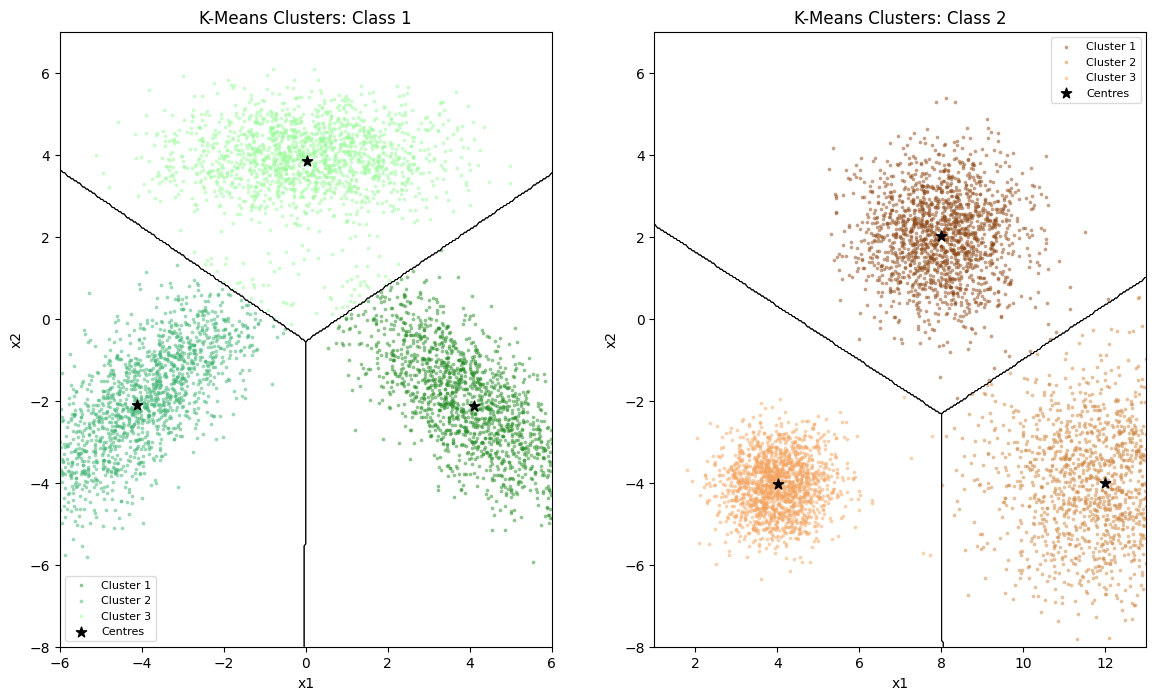

In [42]:
x_ranges = [(-6, 6), (1, 13)]
y_values = np.linspace(-8, 7, 300)

plt.figure(figsize=(12, 7))
for class_index, model in enumerate(class_models):
    samples = train_class_samples[class_index]
    labels = model.predict(samples)

    x_min, x_max = x_ranges[class_index]
    x_values = np.linspace(x_min, x_max, 300)
    x_grid, y_grid = np.meshgrid(x_values, y_values)
    grid_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))
    grid_labels = model.predict(grid_points).reshape(x_grid.shape)

    plt.subplot(1, 2, class_index + 1)
    for k in range(K):
        cluster = samples[labels == k]
        plt.scatter(cluster[:, 0], cluster[:, 1], s=7, alpha=0.5, linewidths=0,
                    color=component_colors[class_index][k], label=f"Cluster {k + 1}")
        plt.contour(x_grid, y_grid, grid_labels == k, levels=[0.5],
                    colors="black", linewidths=0.7)

    plt.scatter(model.centers[:, 0], model.centers[:, 1],
                marker="*", s=60, color="black", label="Centres")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"K-Means Clusters: Class {class_index + 1}")
    plt.legend(fontsize=8, framealpha=0.7)
    plt.axis("scaled")
    plt.xlim(x_min, x_max)
    plt.ylim(-8, 7)

plt.tight_layout()
plt.savefig("figures/kmeans_clusters.png", dpi=200)
plt.show()

### **Test Classification Using Distortion**

In [43]:
def class_distortions(X):
    return np.column_stack([np.min(model.distances(X), axis=1) for model in class_models])


# rows: true class, columns: predicted class
confusion_matrix = np.zeros((2, 2), dtype=int)

for true_class, samples in enumerate(test_class_samples):
    predictions = np.argmin(class_distortions(samples), axis=1)
    for predicted_class in predictions:
        confusion_matrix[true_class, predicted_class] += 1

print("Confusion matrix:\n", confusion_matrix)
print("Accuracy:", np.trace(confusion_matrix) / confusion_matrix.sum())

Confusion matrix:
 [[1107   93]
 [  32 1168]]
Accuracy: 0.9479166666666666


### **Decision Boundary Between the Two Classes**

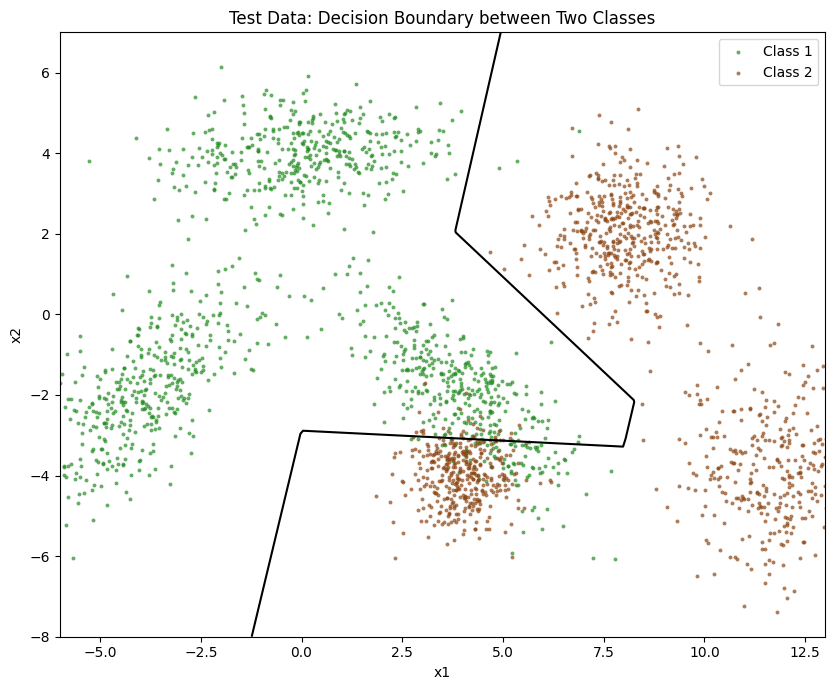

In [44]:
x_values = np.linspace(-6, 13, 300)
y_values = np.linspace(-8, 7, 300)
x_grid, y_grid = np.meshgrid(x_values, y_values)
grid_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))

grid_distortions = class_distortions(grid_points)
difference = (grid_distortions[:, 0] - grid_distortions[:, 1]).reshape(x_grid.shape)

plt.figure(figsize=(9, 7))
for class_index, samples in enumerate(test_class_samples):
    plt.scatter(samples[:, 0], samples[:, 1], s=8, alpha=0.7, linewidths=0,
                color=component_colors[class_index][0], label=f"Class {class_index + 1}")

plt.contour(x_grid, y_grid, difference, levels=[0], colors="black")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Test Data: Decision Boundary between Two Classes")
plt.legend(fontsize=10)
plt.axis("scaled")
plt.xlim(-6, 13)
plt.ylim(-8, 7)
plt.tight_layout()
plt.savefig("figures/decision_boundary.png", dpi=200)
plt.show()